# LGG Segmentation Dataset

This dataset contains brain MR images together with manual FLAIR abnormality segmentation masks. The images were obtained from The Cancer Imaging Archive (TCIA). They correspond to 110 patients included in The Cancer Genome Atlas (TCGA) lower-grade glioma collection with at least fluid-attenuated inversion recovery (FLAIR) sequence and genomic cluster data available. Tumor genomic clusters and patient data is provided in data.csv file.

All images are provided in `.tif` format with 3 channels per image. 
1. For 101 cases, 3 sequences are available, i.e. pre-contrast, FLAIR, post-contrast (in this order of channels).
2. For 9 cases, post-contrast sequence is missing.
3. For 6 cases, pre-contrast sequence is missing.
4. Missing sequences are replaced with FLAIR sequence to make all images 3-channel.
5. Masks are binary, 1-channel images. They segment FLAIR abnormality present in the FLAIR sequence (available for all cases).

The dataset is organized into 110 folders named after case ID that contains information about source institution. Each folder contains MR images with the following naming convention:

`TCGA_<institution-code>_<patient-id>_<slice-number>.tif`

Corresponding masks have a `_mask` suffix.

In [4]:
import os
from pathlib import Path

import pandas as pd

In [5]:
data_dir = Path("/kaggle/input/datasets/mateuszbuda/lgg-mri-segmentation/kaggle_3m")
csv_path = data_dir / "data.csv"

In [6]:
dirs = [item for item in os.listdir(data_dir) if "TCGA" in item]
images_data = []

for dir_name in dirs:
    dir_images = os.listdir(data_dir / dir_name)
    
    for image_name in dir_images:
        if "mask" in image_name:
            continue
    
        masked_image_name = f"{image_name[:-4]}_mask.tif"
        images_data.append([image_name, masked_image_name])

images_df = pd.DataFrame(images_data, columns=["Image", "Mask"])
images_df.head()

,Image,Mask
0,TCGA_DU_7010_19860307_45.tif,TCGA_DU_7010_19860307_45_mask.tif
1,TCGA_DU_7010_19860307_57.tif,TCGA_DU_7010_19860307_57_mask.tif
2,TCGA_DU_7010_19860307_33.tif,TCGA_DU_7010_19860307_33_mask.tif
3,TCGA_DU_7010_19860307_27.tif,TCGA_DU_7010_19860307_27_mask.tif
4,TCGA_DU_7010_19860307_52.tif,TCGA_DU_7010_19860307_52_mask.tif


# Dataset Creation

In [7]:
import cv2
import torch
from torch.utils.data import Dataset

In [8]:
class MRIDataset(Dataset):
    def __init__(self, path=data_dir, dirs=[]):
        self.image_paths = []
        images_data = []
        
        for dir_name in dirs:
            dir_path = data_dir / dir_name
            dir_images = os.listdir(dir_path)
            
            for image_name in dir_images:
                if "mask" in image_name:
                    continue

                image_path = dir_path / image_name
                self.image_paths.append(image_path)

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        image_path = str(self.image_paths[idx])
        mask_path = f"{image_path[:-4]}_mask.tif"

        image = cv2.imread(image_path, cv2.IMREAD_UNCHANGED)
        mask  = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)

        image = torch.from_numpy(image).float().permute(2,0,1) / 255
        mask  = (torch.from_numpy(mask) > 0).float().unsqueeze(0)
        
        return image, mask

In [9]:
import matplotlib.pyplot as plt

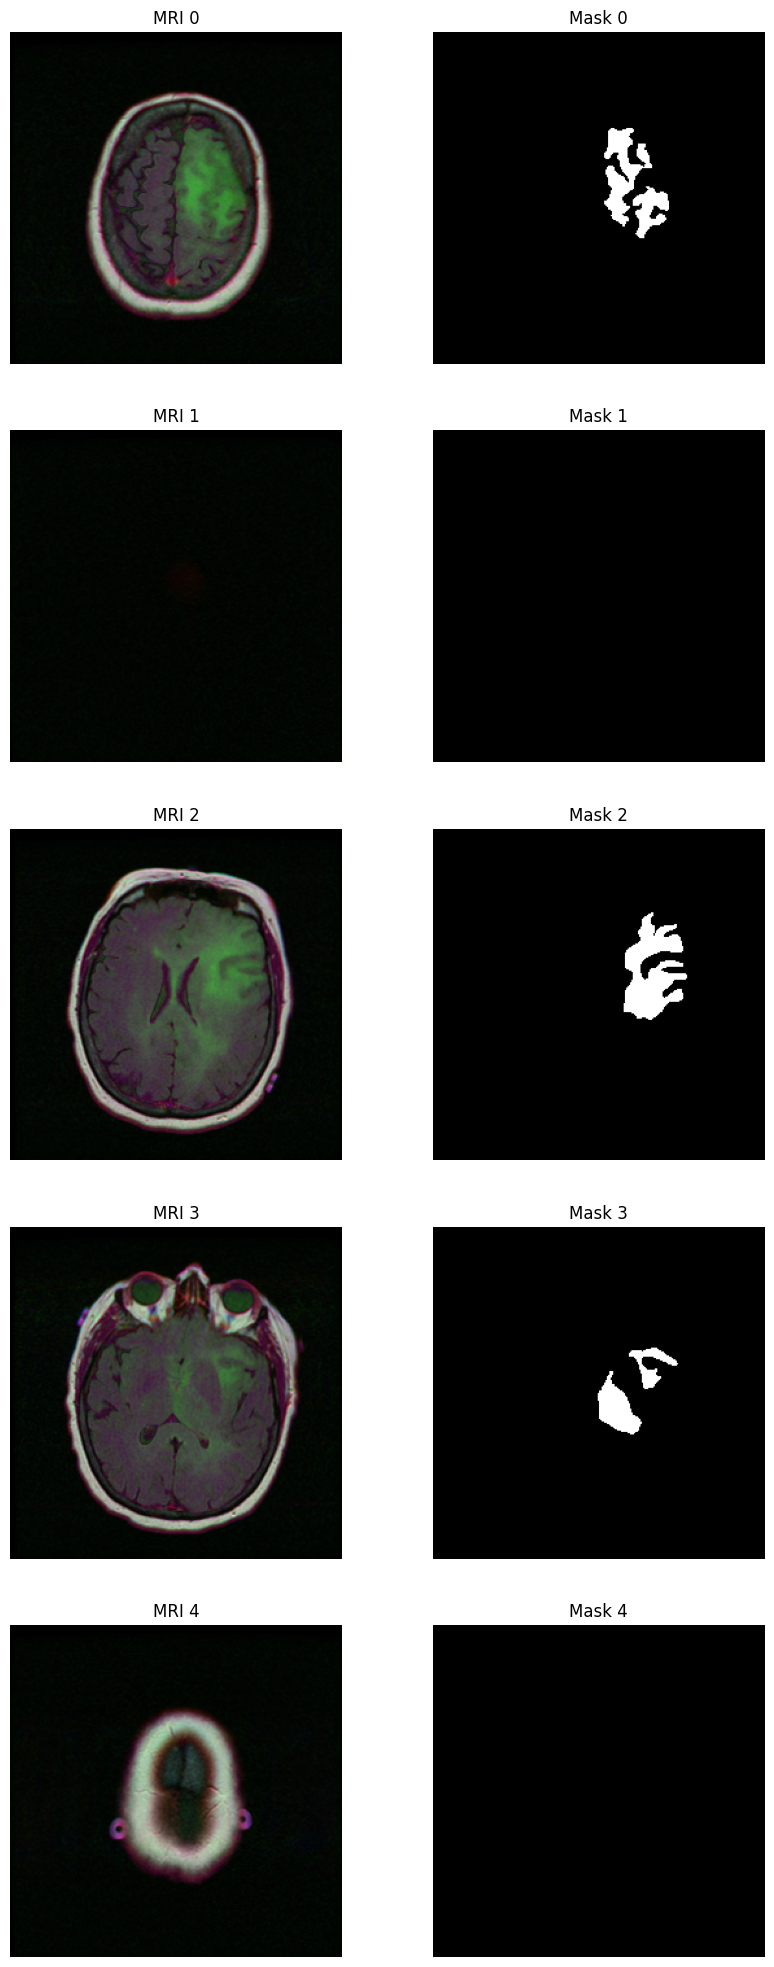

In [10]:
mri_dataset = MRIDataset(dirs=dirs)

def plot_mri_images(indices):
    nrows = len(indices)
    images_subset = [mri_dataset[idx] for idx in indices]
    fig, axes = plt.subplots(nrows,2,figsize=(10,nrows*5))
    
    for idx, (image, mask) in enumerate(images_subset):
        axes[idx][0].imshow(image.permute(1,2,0))
        axes[idx][1].imshow(mask.permute(1,2,0), cmap="gray")

        axes[idx][0].axis("off")
        axes[idx][1].axis("off")

        axes[idx][0].set_title(f"MRI {indices[idx]}")
        axes[idx][1].set_title(f"Mask {indices[idx]}")
        
    plt.show()

plot_mri_images(range(5))

# Baseline UNet

In [11]:
import torch.nn as nn

In [12]:
class DoubleConv(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
        )

    def forward(self, x):
        return self.net(x)

class BaselineUNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.en1 = DoubleConv(3, 64)
        self.en2 = nn.Sequential(nn.MaxPool2d(2), DoubleConv(64, 128))
        self.en3 = nn.Sequential(nn.MaxPool2d(2), DoubleConv(128, 256))

        self.bottleneck = nn.Sequential(nn.MaxPool2d(2), DoubleConv(256, 512))

        self.de1 = nn.ConvTranspose2d(512, 256, kernel_size=2, stride=2)
        self.conv_de1 = DoubleConv(512, 256)

        self.de2 = nn.ConvTranspose2d(256, 128, kernel_size=2, stride=2)
        self.conv_de2 = DoubleConv(256, 128)

        self.de3 = nn.ConvTranspose2d(128, 64, kernel_size=2, stride=2)
        self.conv_de3 = DoubleConv(128, 64)

        self.out = nn.Conv2d(64, 1, kernel_size=1)

    def forward(self, x):
        x1 = self.en1(x)
        x2 = self.en2(x1)
        x3 = self.en3(x2)

        b  = self.bottleneck(x3)


        d1 = self.de1(b)
        d1 = self.conv_de1(torch.cat([d1,x3], dim=1))

        d2 = self.de2(d1)
        d2 = self.conv_de2(torch.cat([d2,x2], dim=1))

        d3 = self.de3(d2)
        d3 = self.conv_de3(torch.cat([d3,x1], dim=1))

        output = self.out(d3)
        
        return output

# Dice Loss Function

In [13]:
class DiceLoss(nn.Module):
    def __init__(self, smooth=1.0):
        super().__init__()
        self.smooth = smooth

    def forward(self, logits, targets):
        probs = torch.sigmoid(logits)

        probs   = probs.view(probs.size(0), -1)
        targets = targets.view(targets.size(0), -1)

        intersection = (probs * targets).sum(dim=1)
        total        = probs.sum(dim=1) + targets.sum(dim=1)
        dice         = (2.0 * intersection + self.smooth) / (total + self.smooth)

        return (1.0 - dice).mean()

class BCEDiceLoss(nn.Module):
    def __init__(self, bce_weight=0.5, smooth=1.0):
        super().__init__()
        self.bce_logits = nn.BCEWithLogitsLoss()
        self.dice = DiceLoss(smooth=smooth)
        self.bce_weight = bce_weight

    def forward(self, logits, targets):
        bce_loss = self.bce_logits(logits, targets)
        dice_loss = self.dice(logits, targets)
        return self.bce_weight * bce_loss + dice_loss

def compute_binary_dice(logits, targets, threshold=0.5, eps=1e-7):
    """Computes hard binary Dice score per image with correct handling of empty slices."""
    probs = torch.sigmoid(logits)
    preds = (probs > threshold).float()

    preds_flat = preds.view(preds.size(0), -1)
    targets_flat = targets.view(targets.size(0), -1)

    intersection = (preds_flat * targets_flat).sum(dim=1)
    cardinality = preds_flat.sum(dim=1) + targets_flat.sum(dim=1)

    dice = (2.0 * intersection) / (cardinality + eps)
    # If both target and prediction are empty, Dice = 1.0 (perfect true negative)
    dice[cardinality == 0] = 1.0

    pos_mask = (targets_flat.sum(dim=1) > 0)
    return dice, pos_mask


# Model Training

In [14]:
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader
import torch.optim as optim
from tqdm.auto import tqdm
import os
from kaggle_secrets import UserSecretsClient
import wandb

user_secrets = UserSecretsClient()
wandb_api_key = user_secrets.get_secret("WANDB_API_KEY")
os.environ['WANDB_API_KEY'] = wandb_api_key

wandb.login(key=wandb_api_key)

/usr/local/lib/python3.13/dist-packages/notebook/notebookapp.py:191: SyntaxWarning: invalid escape sequence '\/'
  | |_| | '_ \/ _` / _` |  _/ -_)
wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: [wandb.login()] Using explicit session credentials for https://api.wandb.ai.
wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: Currently logged in as: sly-of-zero (sly-of-zero-iitm) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


True

In [15]:
TRAINING_CONFIG = {
    "BATCH_SIZE": 4,
    "LR": 3e-4,
    "EPOCHS": 5,
    "EVAL_STEPS": 500,
    "DEVICE": "cuda" if torch.cuda.is_available() else "cpu",

    "Architecture": "UNet",
}

run = wandb.init(
    project="mri-tumor-segmentation",
    id="unet-baseline-run1",
    name="unet-baseline-run1",
    config=TRAINING_CONFIG,
    resume="allow"
)

# Model Setup

In [22]:
# Main model
model = BaselineUNet().to(TRAINING_CONFIG["DEVICE"])

# Dataset and dataloader
train_dirs, val_dirs = train_test_split(dirs, test_size=0.2, random_state=42)
train_ds = MRIDataset(dirs=train_dirs)
val_ds   = MRIDataset(dirs=val_dirs)

train_loader = DataLoader(train_ds, batch_size=TRAINING_CONFIG["BATCH_SIZE"], shuffle=True,  pin_memory=True, num_workers=2)
val_loader   = DataLoader(val_ds,   batch_size=TRAINING_CONFIG["BATCH_SIZE"], shuffle=False, pin_memory=True, num_workers=2)

# Optimizer
optimizer = optim.AdamW(model.parameters(), lr=TRAINING_CONFIG["LR"])

# Criterion
criterion = BCEDiceLoss(bce_weight=1.0, smooth=1.0)

In [23]:
def save_and_upload_model(model, filepath="best_model.pth", metadata=None):
    torch.save(model.state_dict(), filepath)
    
    artifact = wandb.Artifact(
        name="unet-mri-segmentation",
        type="model",
        description="LGG Brain MRI UNet Segmentation Weights",
        metadata=metadata or {}
    )
    
    artifact.add_file(filepath)
    run.log_artifact(artifact)
    print(f"Uploaded {filepath} to W&B Artifacts!")

In [24]:
# Training Loop
training_steps = TRAINING_CONFIG["EPOCHS"] * len(train_loader)
pbar = tqdm(range(training_steps), desc="Training")
tqdm.write(f'Training the model for {TRAINING_CONFIG["EPOCHS"]} epochs on {TRAINING_CONFIG["DEVICE"]}')

best_training_score = 0

for epoch in range(TRAINING_CONFIG["EPOCHS"]):
    model.train()
    running_loss = 0.0
    
    for batch_idx, (images, masks) in enumerate(train_loader):
        step = pbar.n
        optimizer.zero_grad()
        
        images = images.to(TRAINING_CONFIG["DEVICE"])
        masks  = masks.to(TRAINING_CONFIG["DEVICE"])

        pred   = model(images)
        loss   = criterion(pred, masks)
        
        running_loss += loss.item()

        loss.backward()
        optimizer.step()

        if step % TRAINING_CONFIG["EVAL_STEPS"] == 0 and step > 0:
            val_pbar = tqdm(val_loader, desc="Evaluating", leave=False)
            
            model.eval()
            all_dices = []
            pos_dices = []

            with torch.no_grad():
                for val_idx, (val_image, val_label) in enumerate(val_pbar):
                    val_image = val_image.to(TRAINING_CONFIG["DEVICE"])
                    val_label = val_label.to(TRAINING_CONFIG["DEVICE"])
                    
                    val_prediction = model(val_image)
                    dices, pos_mask = compute_binary_dice(val_prediction, val_label)
                    
                    all_dices.extend(dices.cpu().tolist())
                    if pos_mask.any():
                        pos_dices.extend(dices[pos_mask].cpu().tolist())

                    mean_so_far = sum(all_dices) / len(all_dices)
                    pos_so_far = (sum(pos_dices) / len(pos_dices)) if len(pos_dices) > 0 else 0.0
                    val_pbar.set_postfix({
                        "all_dice": f"{mean_so_far:.4f}",
                        "pos_dice": f"{pos_so_far:.4f}"
                    })

            mean_val_dice = sum(all_dices) / len(all_dices)
            mean_pos_dice = sum(pos_dices) / len(pos_dices) if len(pos_dices) > 0 else 0.0
            tqdm.write(f"[Step {step:04d} | Epoch {epoch+1}] Val Dice (Overall): {mean_val_dice:.4f} | Tumor Slices: {mean_pos_dice:.4f}")

            wandb.log({
                "val/val_dice": mean_val_dice,
                "val/tumor_dice": mean_pos_dice,
                "train/running_loss": running_loss / (batch_idx + 1),
                "step": step
            })
            
            if mean_val_dice > best_training_score:
                best_training_score = mean_val_dice
                save_and_upload_model(model, metadata={"BEST_TRAINING_SCORE": best_training_score})
            
            model.train()

        pbar.update()
        pbar.set_postfix({
            "epoch": f"{epoch + 1}/{TRAINING_CONFIG['EPOCHS']}",
            "loss": f"{loss.item():.4f}",
            "avg_loss": f"{running_loss / (batch_idx + 1):.4f}"
        })

pbar.close()

Training:   0%|          | 0/4005 [00:00<?, ?it/s]

Training the model for 5 epochs on cuda


Evaluating:   0%|          | 0/182 [00:00<?, ?it/s]

[Step 0500 | Epoch 1] Val Dice (Overall): 0.6542 | Tumor Slices: 0.5813
Uploaded best_model.pth to W&B Artifacts!


Evaluating:   0%|          | 0/182 [00:00<?, ?it/s]

[Step 1000 | Epoch 2] Val Dice (Overall): 0.6045 | Tumor Slices: 0.5947


KeyboardInterrupt: 

In [26]:
artifact_dir = run.use_artifact("unet-mri-segmentation:latest").download()
artifact_dir

wandb:   1 of 1 files downloaded.  


'/kaggle/working/artifacts/unet-mri-segmentation:v0'

wandb: WARNING Fatal error while uploading data. Some run data will not be synced, but it will still be written to disk. Use `wandb sync` at the end of the run to try uploading.
